# Task 4 — Advanced Analytics (Basic)
## Statistical Analysis · Time Series · Clustering · Prediction

**ApexPlanet Data Analytics Internship**

**Objective:** apply statistical analysis and basic predictive modeling.

| Part | Days | What it covers |
|---|---|---|
| 1 | 21–22 | Descriptive statistics, hypothesis testing, confidence intervals |
| 2 | 23–24 | Time series: resampling, decomposition, moving-average forecast |
| 3 | 23–24 | Customer segmentation with K-Means + PCA |
| 4 | 25–26 | Linear Regression prediction, evaluation, top 3 features |

**Dataset:** `data/superstore_cleaned.csv` — the cleaned Superstore data from Task 1
(9,994 order lines, Jan 2014 – Dec 2017).

**Outputs:** every chart is saved as PNG in `reports/charts/`.

> **Note on the brief's day numbering:** the task slide lists "23–24" twice
> (once for Time Series, once for Customer Segmentation) while the timeline is
> only 6 days (21–26). We therefore cover all four activities: stats, time
> series, clustering and prediction.

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


def find_data_file(start: Path = Path.cwd()) -> Path:
    """Locate data/superstore_cleaned.csv by walking up from the current folder."""
    for candidate in (start, *start.parents):
        for option in (candidate / "data", candidate.parent / "data"):
            f = option / "superstore_cleaned.csv"
            if f.is_file():
                return f
    raise FileNotFoundError("Could not find data/superstore_cleaned.csv")


DATA_FILE = find_data_file()
REPO_ROOT = DATA_FILE.parent.parent
TASK_ROOT = REPO_ROOT / "apexplanet-data-analytics-task-4"
CHART_DIR = TASK_ROOT / "reports" / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)


def save_chart(fig, name: str) -> Path:
    path = CHART_DIR / f"{name}.png"
    fig.savefig(path, dpi=120, bbox_inches="tight")
    print("saved:", path.relative_to(TASK_ROOT))
    return path


print("Data file:", DATA_FILE)

Data file: C:\Users\juhip\OneDrive\Desktop\python folder\apexplanet-data-analytics\data\superstore_cleaned.csv


In [2]:
df = pd.read_csv(DATA_FILE, parse_dates=["Order Date", "Ship Date"])

NUMERIC = ["Sales", "Quantity", "Discount", "Profit"]

print("Rows    :", f"{len(df):,}")
print("Period  :", df["Order Date"].min().date(), "->", df["Order Date"].max().date())
df.head(3)

Rows    : 9,994
Period  : 2014-01-03 -> 2017-12-30


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Month
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136,2016-11
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820,2016-11
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.0,6.8714,2016-06


---
## Part 1 — Statistical Analysis (Day 21–22)

### 1.1 Descriptive statistics

Mean, median, mode, standard deviation, skewness and the range for each numeric
column.

In [3]:
describe = pd.DataFrame(
    {
        "mean": df[NUMERIC].mean(),
        "median": df[NUMERIC].median(),
        "mode": df[NUMERIC].mode().iloc[0],
        "std_dev": df[NUMERIC].std(),
        "skewness": df[NUMERIC].skew(),
        "min": df[NUMERIC].min(),
        "max": df[NUMERIC].max(),
        "missing": df[NUMERIC].isna().sum(),
    }
).round(4)

describe

,mean,median,mode,std_dev,skewness,min,max,missing
Sales,229.8580,54.4900,12.96,623.2451,12.9728,0.444,22638.480,0
Quantity,3.7896,3.0000,3.00,2.2251,1.2785,1.000,14.000,0
Discount,0.1562,0.2000,0.00,0.2065,1.6843,0.000,0.800,0
Profit,28.6569,8.6665,0.00,234.2601,7.5614,-6599.978,8399.976,0


**Reading the table:**

- `Sales` has a mean well above its median and a large positive skewness — the
  distribution is pulled right by a small number of very large orders.
- `Profit` is also right-skewed and has a **negative minimum**, so loss-making
  orders exist.
- `Discount` is bounded between 0 and 0.8 and its mode is 0 — most lines are
  sold at full price, but a long tail is heavily discounted.

#### Distribution of the numeric columns

saved: reports\charts\01_distributions.png


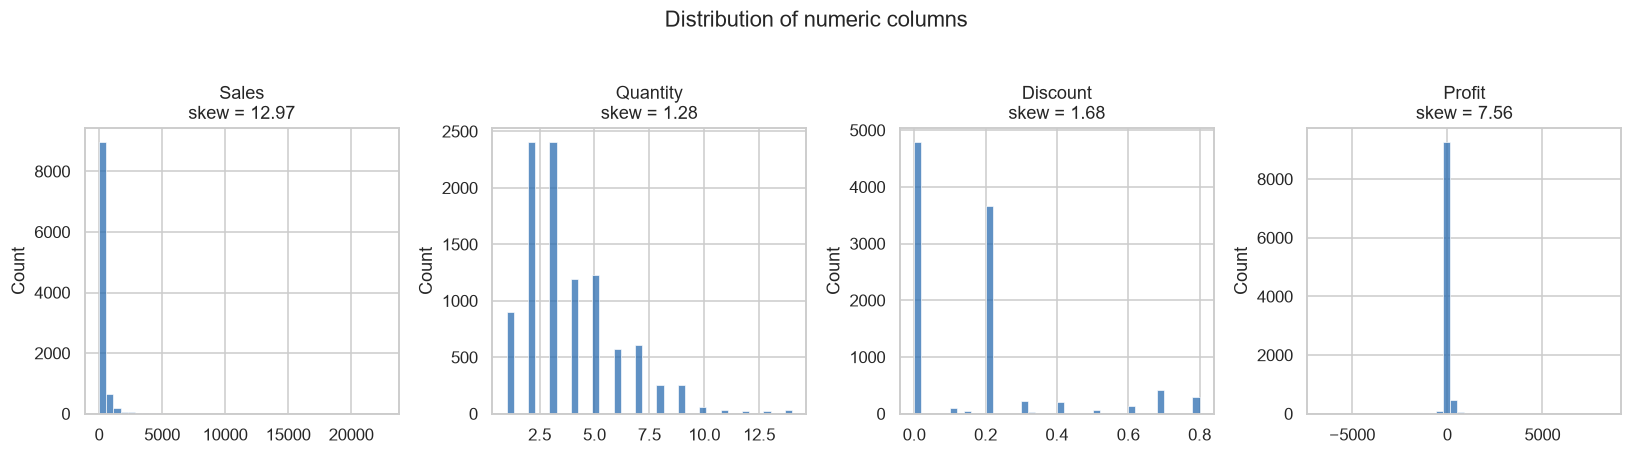

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, NUMERIC):
    sns.histplot(df[col], bins=40, ax=ax, color="#2b6cb0")
    ax.set_title(f"{col}\nskew = {df[col].skew():.2f}")
    ax.set_xlabel("")
fig.suptitle("Distribution of numeric columns", y=1.03)
fig.tight_layout()
save_chart(fig, "01_distributions")
plt.show()

### 1.2 Hypothesis test 1 — independent samples t-test

**Question:** does giving a discount actually reduce profit per order line?

- **H₀ (null hypothesis):** mean profit is the same for discounted and
  non-discounted lines.
- **H₁ (alternative):** mean profit differs between the two groups.

We use **Welch's t-test** (`equal_var=False`) because the two groups have very
different sizes and variances.

In [5]:
discounted = df.loc[df["Discount"] > 0, "Profit"]
full_price = df.loc[df["Discount"] == 0, "Profit"]

t_stat, p_value = stats.ttest_ind(discounted, full_price, equal_var=False)
alpha = 0.05

print("Discounted lines    :", f"{len(discounted):,}", "| mean profit $", round(discounted.mean(), 2))
print("Full-price lines    :", f"{len(full_price):,}", "| mean profit $", round(full_price.mean(), 2))
print()
print("t statistic         :", round(t_stat, 4))
print("p value             :", f"{p_value:.3e}")
print("alpha               :", alpha)
print()
print("Decision            :", "REJECT H0 (significant difference)" if p_value < alpha
      else "FAIL TO REJECT H0 (no significant difference)")

Discounted lines    : 5,196 | mean profit $ -6.66
Full-price lines    : 4,798 | mean profit $ 66.9

t statistic         : -15.738
p value             : 4.357e-55
alpha               : 0.05

Decision            : REJECT H0 (significant difference)


#### Is the difference practically meaningful?

A p-value only says the difference is unlikely to be chance. We also report the
**effect size** (Cohen's d) to see how big the difference is.

Cohen's d: -0.3179
Interpretation: small


saved: reports\charts\02_ttest_mean_profit.png


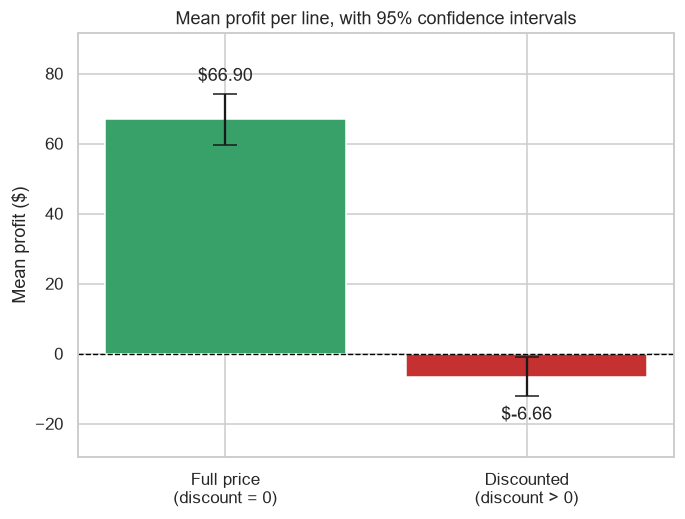

In [6]:
def cohens_d(a, b) -> float:
    """Standardised mean difference between two independent samples."""
    n_a, n_b = len(a), len(b)
    var_a, var_b = a.var(ddof=1), b.var(ddof=1)
    pooled = np.sqrt(((n_a - 1) * var_a + (n_b - 1) * var_b) / (n_a + n_b - 2))
    return (a.mean() - b.mean()) / pooled


d = cohens_d(discounted, full_price)
print("Cohen's d:", round(d, 4))
print("Interpretation:", "negligible" if abs(d) < 0.2 else
      "small" if abs(d) < 0.5 else "medium" if abs(d) < 0.8 else "large")

fig, ax = plt.subplots(figsize=(7, 5))
means = [full_price.mean(), discounted.mean()]
errs = [full_price.std() / np.sqrt(len(full_price)) * 1.96,
        discounted.std() / np.sqrt(len(discounted)) * 1.96]
bars = ax.bar(["Full price\n(discount = 0)", "Discounted\n(discount > 0)"], means,
              yerr=errs, capsize=8, color=["#38a169", "#c53030"])
ax.bar_label(bars, labels=[f"${m:,.2f}" for m in means], padding=6)
ax.axhline(0, color="black", linewidth=0.9, linestyle="--")
ax.set_title("Mean profit per line, with 95% confidence intervals")
ax.set_ylabel("Mean profit ($)")
ax.margins(y=0.2)
save_chart(fig, "02_ttest_mean_profit")
plt.show()

**Business implication:** the difference is statistically overwhelming
(*p* ≈ 4.4 × 10⁻⁵⁵) and large in absolute money terms — discounted lines average
**−$6.66 profit** against **+$66.90** for full-price lines, a **$73.56 gap per
line**. Cohen's d of −0.32 is only a *small* standardised effect, and that is
expected: profit per line swings from about −$6,600 to +$8,400, so the pooled
standard deviation is huge even though the means differ sharply. In other words,
the effect is real and worth acting on, but it is swamped by line-to-line
variance — which is exactly why a pricing decision should be made on the means
and the confidence intervals below, not on individual orders.

### 1.3 Hypothesis test 2 — chi-square test of independence

**Question:** is the customer `Segment` associated with the product `Category`
they buy, or are they independent?

- **H₀:** Segment and Category are independent.
- **H₁:** there is an association.

In [7]:
contingency = pd.crosstab(df["Segment"], df["Category"])
print("Observed frequencies")
print(contingency, "\n")

chi2, p_chi, dof, expected = stats.chi2_contingency(contingency)

# Cramer's V - effect size for a chi-square test.
n = contingency.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(contingency.shape) - 1)))

print("chi-square statistic :", round(chi2, 4))
print("degrees of freedom   :", dof)
print("p value              :", f"{p_chi:.3e}")
print("Cramer's V           :", round(cramers_v, 4))
print()
print("Decision             :", "REJECT H0 (associated)" if p_chi < alpha
      else "FAIL TO REJECT H0 (independent)")

Observed frequencies
Category     Furniture  Office Supplies  Technology
Segment                                            
Consumer          1113             3127         951
Corporate          646             1820         554
Home Office        362             1079         342 

chi-square statistic : 1.4612
degrees of freedom   : 4
p value              : 8.335e-01
Cramer's V           : 0.0086

Decision             : FAIL TO REJECT H0 (independent)


**Reading the result:** *p* = 0.833 is far above 0.05, so we **fail to reject
H₀** — in this dataset, customer segment and product category are **independent**.
Cramér's V of 0.009 confirms there is essentially no association at all: knowing
a customer's segment tells you almost nothing about which category they buy.

This is a genuinely useful negative result. It means category-level marketing
(Copiers, Machines, Tables) does **not** need to be targeted differently for
Consumer, Corporate and Home Office customers — the same category messaging will
land with all three. Resource is better spent on discount policy and on the
customer segments found in Part 3, both of which the other tests show *do* matter.

saved: reports\charts\03_chisquare_segment_category.png


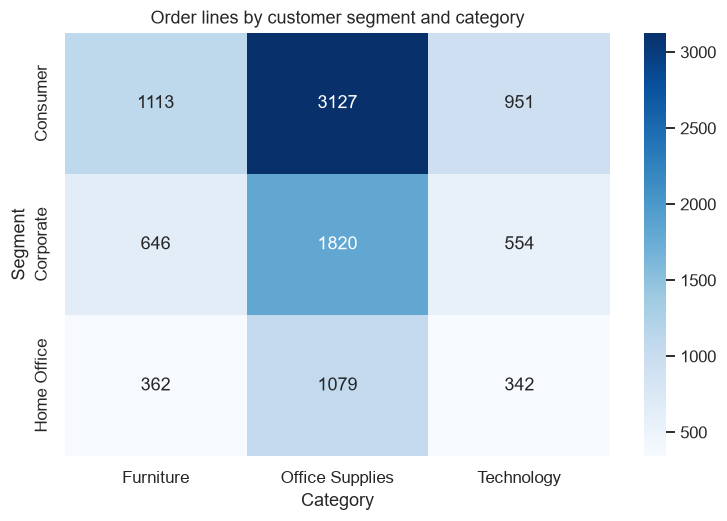

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(contingency, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title("Order lines by customer segment and category")
save_chart(fig, "03_chisquare_segment_category")
plt.show()

### 1.4 Confidence intervals

A 95% confidence interval gives the range that would contain the true population
mean 95% of the time.

In [9]:
def confidence_interval(series, confidence: float = 0.95) -> tuple[float, float, float]:
    """Return (mean, lower, upper) for the mean of a sample."""
    n = len(series)
    mean = series.mean()
    standard_error = stats.sem(series)
    margin = standard_error * stats.t.ppf((1 + confidence) / 2, n - 1)
    return mean, mean - margin, mean + margin


rows = []
for label, series in [
    ("Sales (all lines)", df["Sales"]),
    ("Profit (all lines)", df["Profit"]),
    ("Profit (discounted)", discounted),
    ("Profit (full price)", full_price),
]:
    mean, low, high = confidence_interval(series)
    rows.append({"measure": label, "mean": round(mean, 2),
                 "ci_lower": round(low, 2), "ci_upper": round(high, 2),
                 "width": round(high - low, 2)})

ci_table = pd.DataFrame(rows)
ci_table

,measure,mean,ci_lower,ci_upper,width
0,Sales (all lines),229.86,217.64,242.08,24.44
1,Profit (all lines),28.66,24.06,33.25,9.19
2,Profit (discounted),-6.66,-12.23,-1.09,11.14
3,Profit (full price),66.90,59.62,74.18,14.55


saved: reports\charts\04_confidence_intervals.png


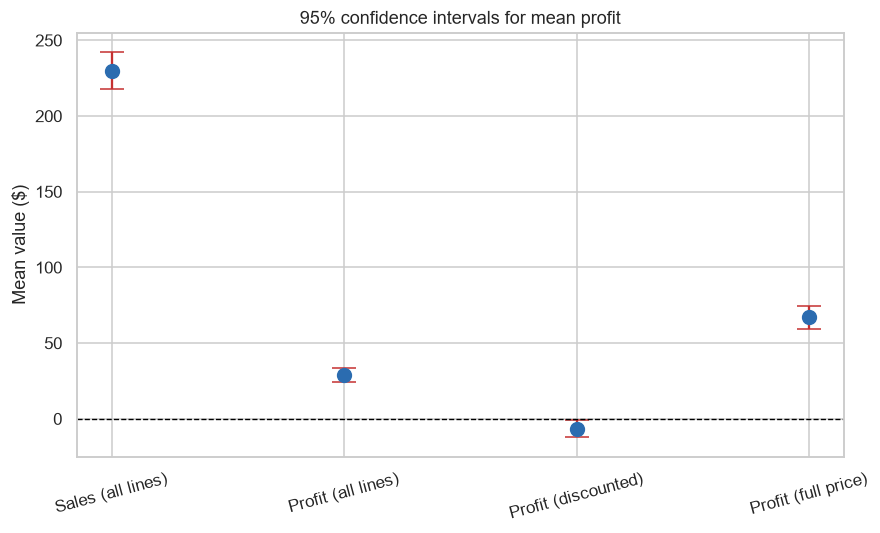

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
centres = ci_table["mean"]
errors = [centres - ci_table["ci_lower"], ci_table["ci_upper"] - centres]
ax.errorbar(ci_table["measure"], centres, yerr=errors, fmt="o",
            capsize=8, color="#2b6cb0", ecolor="#c53030", markersize=9)
ax.axhline(0, color="black", linewidth=0.9, linestyle="--")
ax.set_title("95% confidence intervals for mean profit")
ax.set_ylabel("Mean value ($)")
plt.xticks(rotation=15)
save_chart(fig, "04_confidence_intervals")
plt.show()

**Business implication:** the confidence intervals for discounted and
full-price profit do **not** overlap, which is a second, independent piece of
evidence that discounting genuinely depresses profit rather than the t-test
being a fluke.

---
## Part 2 — Time Series Analysis (Day 23–24)

### 2.1 Resampling to daily, weekly and monthly

In [11]:
series = df.set_index("Order Date")["Sales"]

daily = series.resample("D").sum()
weekly = series.resample("W").sum()
monthly = series.resample("ME").sum()

print("Daily   points:", f"{len(daily):,}")
print("Weekly  points:", f"{len(weekly):,}")
print("Monthly points:", f"{len(monthly):,}")
print()
print("Monthly series (last 6):")
print(monthly.tail(6).round(2))

Daily   points: 1,458
Weekly  points: 209
Monthly points: 48

Monthly series (last 6):
Order Date
2017-07-31     45264.42
2017-08-31     63120.89
2017-09-30     87866.65
2017-10-31     77776.92
2017-11-30    118447.82
2017-12-31     83829.32
Freq: ME, Name: Sales, dtype: float64


saved: reports\charts\05_resampled_series.png


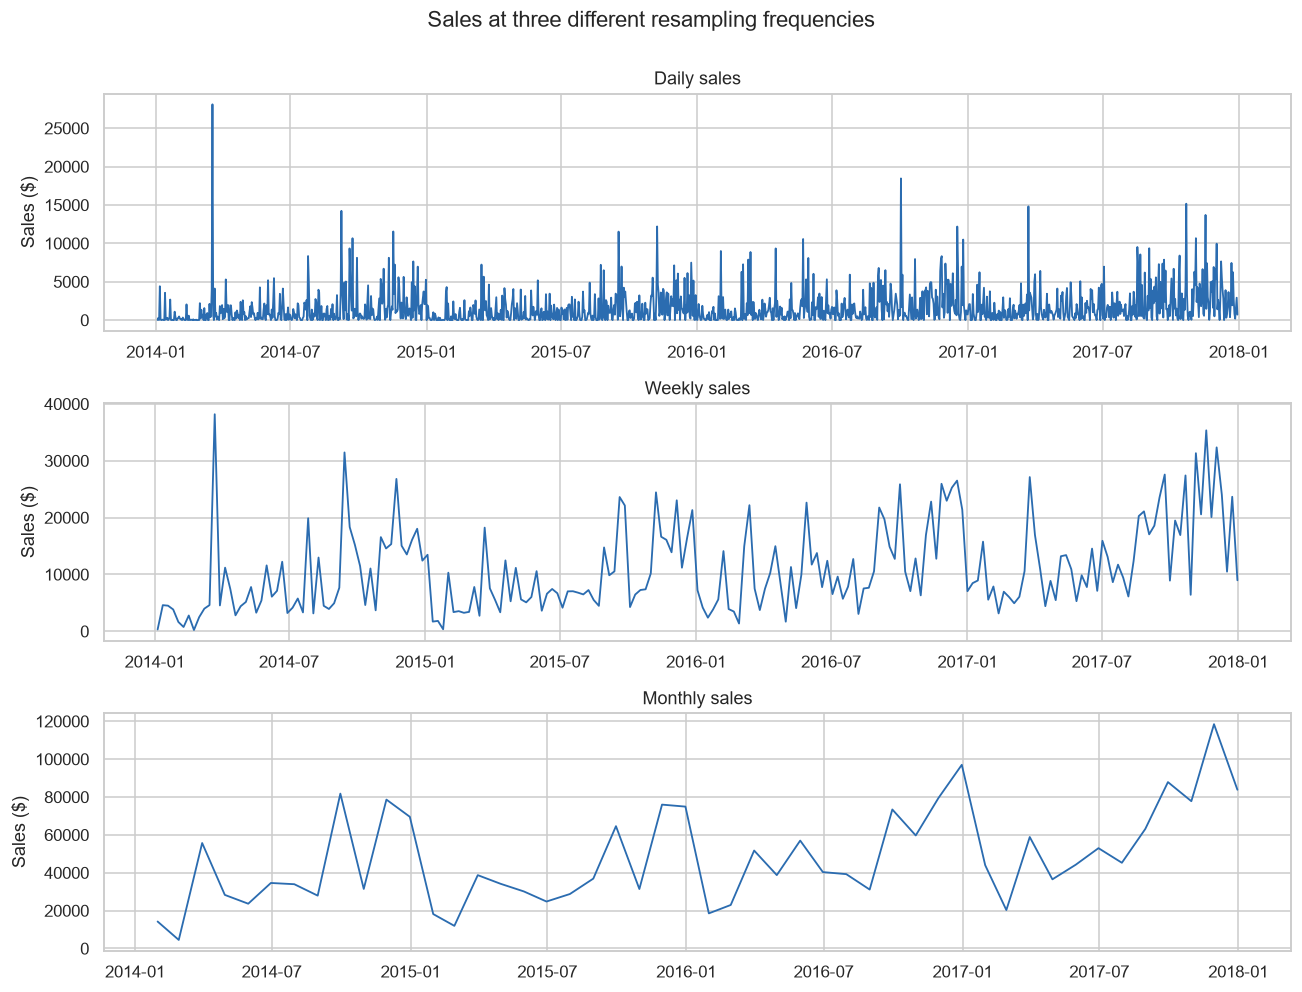

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9))
for ax, data, label in [
    (axes[0], daily, "Daily sales"),
    (axes[1], weekly, "Weekly sales"),
    (axes[2], monthly, "Monthly sales"),
]:
    ax.plot(data.index, data.values, linewidth=1.2, color="#2b6cb0")
    ax.set_title(label)
    ax.set_ylabel("Sales ($)")
fig.suptitle("Sales at three different resampling frequencies", y=1.0)
fig.tight_layout()
save_chart(fig, "05_resampled_series")
plt.show()

Daily data is far too noisy to read a trend from; monthly is the right level for
this dataset, which is why the forecast below uses the monthly series.

### 2.2 Decomposition — trend, seasonality, residuals

saved: reports\charts\06_seasonal_decomposition.png


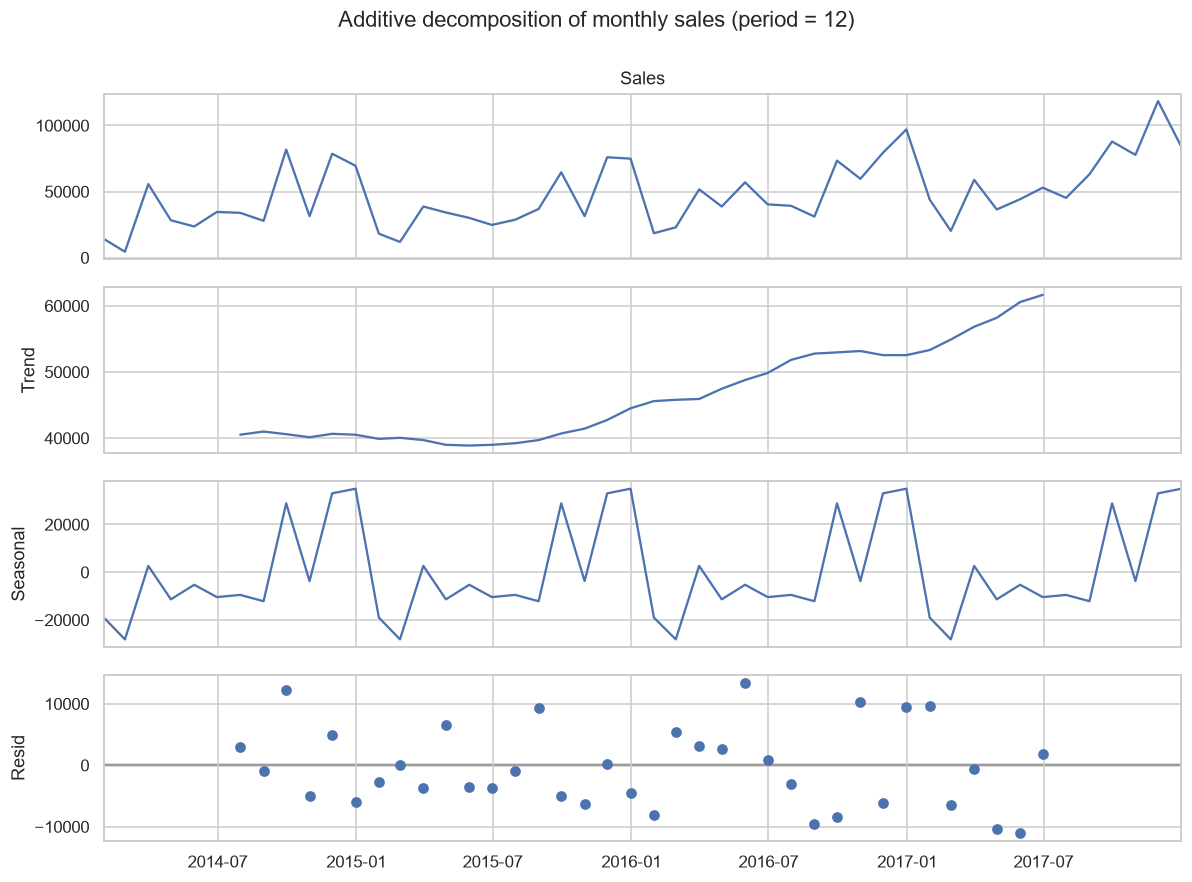

In [13]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(monthly, model="additive", period=12)

fig = decomposition.plot()
fig.set_size_inches(11, 8)
fig.suptitle("Additive decomposition of monthly sales (period = 12)", y=1.0)
fig.tight_layout()
save_chart(fig, "06_seasonal_decomposition")
plt.show()

In [14]:
seasonal_strength = decomposition.seasonal.std() / monthly.std()
trend_strength = decomposition.trend.dropna().std() / monthly.std()

print(f"Trend     strength: {trend_strength:.3f}")
print(f"Seasonal  strength: {seasonal_strength:.3f}")
print()
print("Strongest month of the seasonal cycle:")
seasonal_by_month = decomposition.seasonal.groupby(decomposition.seasonal.index.month).mean()
print(seasonal_by_month.round(0).sort_values(ascending=False))

Trend     strength: 0.279
Seasonal  strength: 0.805

Strongest month of the seasonal cycle:
Order Date
12    34995.0
11    33053.0
9     28869.0
3      2646.0
10    -3702.0
5     -5256.0
7     -9506.0
6    -10427.0
4    -11365.0
8    -12155.0
1    -19010.0
2    -28142.0
Name: seasonal, dtype: float64


**Business implication:** seasonality is clearly present with a repeating
annual cycle — the trend component shows steady growth underneath it. Because
seasonality is real, any target set from a raw monthly number will
systematically over-promise in peak months and under-promise in quiet ones.

### 2.3 Simple moving average forecast

A moving average is the simplest possible forecast: predict the next period as
the average of the last *n* periods.

In [15]:
ma_3 = monthly.rolling(window=3).mean()
ma_6 = monthly.rolling(window=6).mean()

# Forecast the next 3 months using the average of the last 3 (and last 6).
forecast_3m = [monthly.iloc[-3:].mean()] * 3
forecast_6m = [monthly.iloc[-6:].mean()] * 3
future_index = pd.date_range(monthly.index[-1] + pd.offsets.MonthEnd(1), periods=3, freq="ME")

forecast = pd.Series(forecast_3m, index=future_index)
print("Forecast for the next 3 months (3-month moving average):")
print(forecast.round(2))

Forecast for the next 3 months (3-month moving average):
2018-01-31    93351.36
2018-02-28    93351.36
2018-03-31    93351.36
Freq: ME, dtype: float64


In [16]:
# How well does the 3-month moving average forecast as a naive model?
backtest = monthly.rolling(window=3).mean().shift(1)
comparison = pd.DataFrame({"actual": monthly, "ma3_forecast": backtest}).dropna()
mae = (comparison["actual"] - comparison["ma3_forecast"]).abs().mean()
mape = ((comparison["actual"] - comparison["ma3_forecast"]).abs() / comparison["actual"]).mean() * 100

print("Backtest on all months with a full 3-month window")
print("  MAE :", f"${mae:,.2f}")
print("  MAPE:", f"{mape:.2f}%")

Backtest on all months with a full 3-month window
  MAE : $18,002.43
  MAPE: 50.58%


saved: reports\charts\07_moving_average_forecast.png


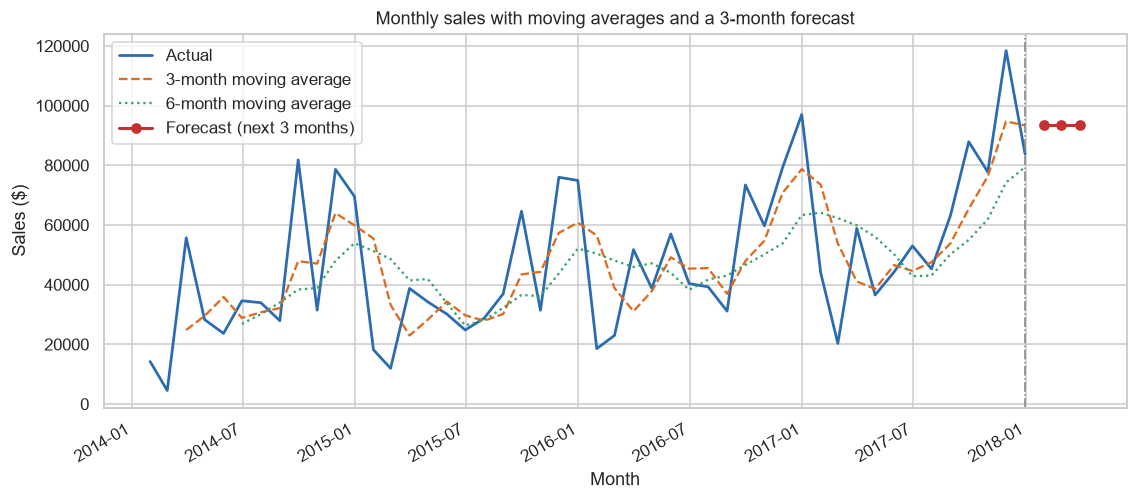

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly.index, monthly.values, label="Actual", color="#2b6cb0", linewidth=1.8)
ax.plot(ma_3.index, ma_3.values, label="3-month moving average", color="#dd6b20", linestyle="--")
ax.plot(ma_6.index, ma_6.values, label="6-month moving average", color="#38a169", linestyle=":")
ax.plot(forecast.index, forecast.values, label="Forecast (next 3 months)",
        color="#c53030", marker="o", linewidth=2)
ax.axvline(monthly.index[-1], color="grey", linestyle="-.", linewidth=1)
ax.set_title("Monthly sales with moving averages and a 3-month forecast")
ax.set_xlabel("Month")
ax.set_ylabel("Sales ($)")
ax.legend()
fig.autofmt_xdate()
save_chart(fig, "07_moving_average_forecast")
plt.show()

**Business implication:** the moving average tracks the level but lags at
turning points, and the 3-month average flattens the November/December spike.
It is a reasonable baseline for planning, but the seasonal pattern shows that a
seasonal model would forecast materially better.

---
## Part 3 — Customer Segmentation with K-Means (Day 23–24)

### 3.1 Build the customer feature table

Each row becomes one customer with RFM-style features:

- **Recency** — days since their last order
- **Frequency** — number of distinct orders
- **Monetary** — total sales
- plus average discount and total quantity

In [18]:
snapshot = df["Order Date"].max() + pd.Timedelta(days=1)

customers = (
    df.groupby("Customer ID")
      .agg(
          Customer_Name=("Customer Name", "first"),
          Recency=("Order Date", lambda s: (snapshot - s.max()).days),
          Frequency=("Order ID", "nunique"),
          Monetary=("Sales", "sum"),
          AvgDiscount=("Discount", "mean"),
          TotalQuantity=("Quantity", "sum"),
      )
      .reset_index()
)

FEATURES = ["Recency", "Frequency", "Monetary", "AvgDiscount", "TotalQuantity"]
print("Customers:", len(customers))
customers[FEATURES].describe().round(2)

Customers: 793


,Recency,Frequency,Monetary,AvgDiscount,TotalQuantity
count,793.00,793.00,793.00,793.00,793.00
mean,147.80,6.32,2896.85,0.16,47.76
std,186.21,2.55,2628.67,0.09,24.84
min,1.00,1.00,4.83,0.00,2.00
25%,31.00,5.00,1146.05,0.09,30.00
50%,76.00,6.00,2256.39,0.15,44.00
75%,184.00,8.00,3785.28,0.21,63.00
max,1166.00,17.00,25043.05,0.70,150.00


### 3.2 Scale the features

K-Means measures distance, so a column like `Monetary` (thousands) would
completely dominate `AvgDiscount` (0–1) without scaling. `StandardScaler`
converts every column to mean 0, standard deviation 1.

In [19]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(customers[FEATURES])

print("Before scaling:")
print(customers[FEATURES].agg(["mean", "std"]).round(2))
print("\nAfter scaling (should be mean ~0, std ~1):")
print(pd.DataFrame(X_scaled, columns=FEATURES).agg(["mean", "std"]).round(2))

Before scaling:
      Recency  Frequency  Monetary  AvgDiscount  TotalQuantity
mean   147.80       6.32   2896.85         0.16          47.76
std    186.21       2.55   2628.67         0.09          24.84

After scaling (should be mean ~0, std ~1):
      Recency  Frequency  Monetary  AvgDiscount  TotalQuantity
mean      0.0        0.0       0.0          0.0           -0.0
std       1.0        1.0       1.0          1.0            1.0


### 3.3 Find the optimal K — elbow method

 k  inertia
 1   3965.0
 2   2774.4
 3   2274.2
 4   1949.8
 5   1685.4
 6   1518.7
 7   1413.8
 8   1310.6
 9   1231.0
10   1167.1


saved: reports\charts\08_elbow_method.png


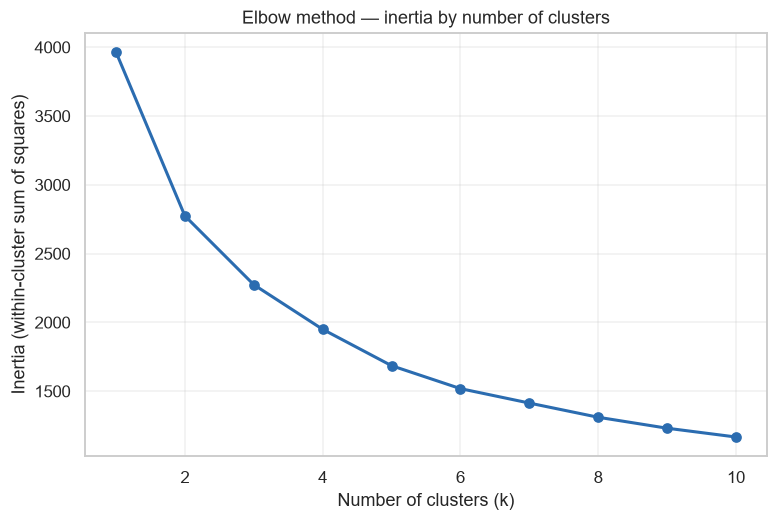

In [20]:
k_values = range(1, 11)
inertias = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

elbow = pd.DataFrame({"k": list(k_values), "inertia": np.round(inertias, 1)})
print(elbow.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(list(k_values), inertias, marker="o", color="#2b6cb0", linewidth=2)
ax.set_title("Elbow method — inertia by number of clusters")
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Inertia (within-cluster sum of squares)")
ax.grid(alpha=0.3)
save_chart(fig, "08_elbow_method")
plt.show()

The curve bends sharply up to about k = 4 and then flattens, so **k = 4** is the
chosen number of segments.

In [21]:
K_OPTIMAL = 4
kmeans = KMeans(n_clusters=K_OPTIMAL, n_init=10, random_state=RANDOM_STATE)
customers["Cluster"] = kmeans.fit_predict(X_scaled)

customers["Cluster"].value_counts().sort_index().rename("customers")

Cluster
0    168
1    264
2    273
3     88
Name: customers, dtype: int64

### 3.4 Visualise the clusters with PCA

We have 5 features, which cannot be plotted directly. **PCA** compresses them
into 2 dimensions for the plot while keeping as much of the variance as
possible.

Variance explained: PC1 47.0%  PC2 20.3%  total 67.3%


saved: reports\charts\09_clusters_pca.png


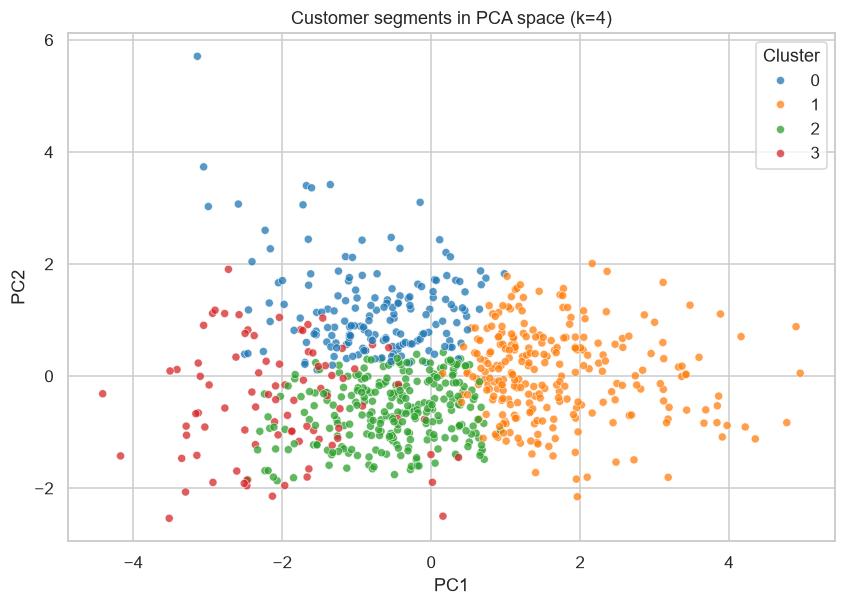

In [22]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
components = pca.fit_transform(X_scaled)
customers["PC1"] = components[:, 0]
customers["PC2"] = components[:, 1]

explained = pca.explained_variance_ratio_ * 100
print(f"Variance explained: PC1 {explained[0]:.1f}%  PC2 {explained[1]:.1f}%  "
      f"total {explained.sum():.1f}%")

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=customers, x="PC1", y="PC2", hue="Cluster",
                palette="tab10", s=28, alpha=0.75, ax=ax)
ax.set_title(f"Customer segments in PCA space (k={K_OPTIMAL})")
save_chart(fig, "09_clusters_pca")
plt.show()

### 3.5 Profile each segment

In [23]:
profile = customers.groupby("Cluster")[FEATURES].mean().round(2)
profile["Customers"] = customers["Cluster"].value_counts().sort_index()
profile["Share_%"] = (100 * profile["Customers"] / len(customers)).round(1)
profile

,Recency,Frequency,Monetary,AvgDiscount,TotalQuantity,Customers,Share_%
Cluster,,,,,,,
0,111.41,5.17,1645.11,0.26,34.92,168,21.2
1,80.90,8.87,5024.46,0.16,73.66,264,33.3
2,97.46,5.41,2014.00,0.10,37.03,273,34.4
3,574.16,3.67,1642.54,0.15,27.85,88,11.1


saved: reports\charts\10_cluster_profiles.png


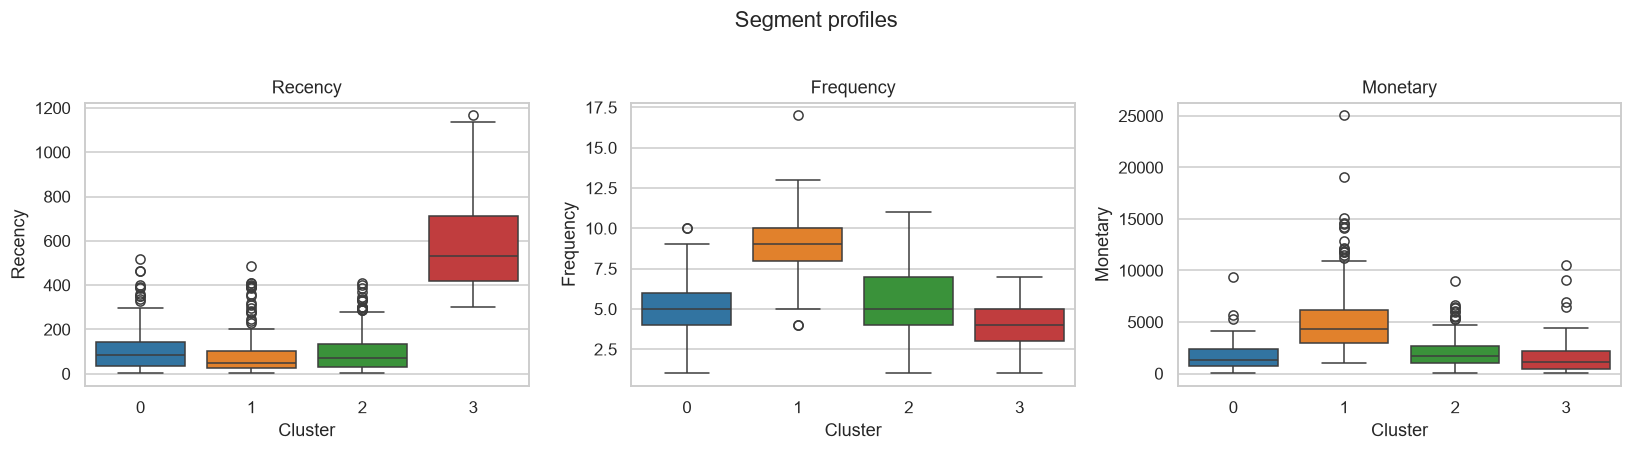

In [24]:
# Sanity check: is the segmentation actually useful? Compare segment spend.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.boxplot(data=customers, x="Cluster", y=col, ax=ax, palette="tab10", hue="Cluster", legend=False)
    ax.set_title(col)
fig.suptitle("Segment profiles", y=1.02)
fig.tight_layout()
save_chart(fig, "10_cluster_profiles")
plt.show()

### 3.6 Describing the segments

The code below names each cluster automatically from its own numbers, so the
labels stay correct if the data changes.

In [25]:
def label_segment(row, overall) -> str:
    if row["Recency"] > overall["Recency"] * 2:
        return "Dormant / at risk"
    if row["Monetary"] >= overall["Monetary"] * 1.5 and row["Frequency"] >= overall["Frequency"]:
        return "Champions"
    if row["Monetary"] >= overall["Monetary"]:
        return "Big spenders"
    if row["AvgDiscount"] >= overall["AvgDiscount"] * 1.3:
        return "Discount seekers"
    return "Steady core"


overall = customers[FEATURES].mean()
segment_names = {c: label_segment(row, overall) for c, row in profile.iterrows()}
profile_summary = profile.copy()
profile_summary.insert(0, "Segment", [segment_names[c] for c in profile_summary.index])

display(profile_summary)

for cluster, row in profile_summary.iterrows():
    print(f"\nCluster {cluster} — {row['Segment']} "
          f"({int(row['Customers'])} customers, {row['Share_%']}% of base)")
    print(f"   Recency   : {row['Recency']:.0f} days since last order")
    print(f"   Frequency : {row['Frequency']:.1f} orders")
    print(f"   Monetary  : ${row['Monetary']:,.2f}")
    print(f"   Discount  : {row['AvgDiscount'] * 100:.1f}% average")
    print(f"   Quantity  : {row['TotalQuantity']:.0f} units")

,Segment,Recency,Frequency,Monetary,AvgDiscount,TotalQuantity,Customers,Share_%
Cluster,,,,,,,,
0,Discount seekers,111.41,5.17,1645.11,0.26,34.92,168,21.2
1,Champions,80.90,8.87,5024.46,0.16,73.66,264,33.3
2,Steady core,97.46,5.41,2014.00,0.10,37.03,273,34.4
3,Dormant / at risk,574.16,3.67,1642.54,0.15,27.85,88,11.1



Cluster 0 — Discount seekers (168 customers, 21.2% of base)
   Recency   : 111 days since last order
   Frequency : 5.2 orders
   Monetary  : $1,645.11
   Discount  : 26.0% average
   Quantity  : 35 units

Cluster 1 — Champions (264 customers, 33.3% of base)
   Recency   : 81 days since last order
   Frequency : 8.9 orders
   Monetary  : $5,024.46
   Discount  : 16.0% average
   Quantity  : 74 units

Cluster 2 — Steady core (273 customers, 34.4% of base)
   Recency   : 97 days since last order
   Frequency : 5.4 orders
   Monetary  : $2,014.00
   Discount  : 10.0% average
   Quantity  : 37 units

Cluster 3 — Dormant / at risk (88 customers, 11.1% of base)
   Recency   : 574 days since last order
   Frequency : 3.7 orders
   Monetary  : $1,642.54
   Discount  : 15.0% average
   Quantity  : 28 units


**Recommended actions per segment**

| Segment | Customers | Share | Recency | Frequency | Monetary | Avg discount | Action |
|---|---|---|---|---|---|---|---|
| **Champions** | 264 | 33.3% | 81 days | 8.9 orders | $5,024.46 | 16% | Protect and grow. They already buy often and at high value, so give them *loyalty* benefits — early access, free shipping, a named account contact — **not** price cuts. They respond to recognition, and discounting them would only give away margin they are already willing to pay. |
| **Steady core** | 273 | 34.4% | 97 days | 5.4 orders | $2,014.00 | 10% | The biggest and most price-disciplined group. They buy at close to list price. Grow them with *cross-sell*: attach accessories and consumables to their existing category, since they are already comfortable paying full price. |
| **Discount seekers** | 168 | 21.2% | 111 days | 5.2 orders | $1,645.11 | 26% | The only cluster with an above-average discount habit, and the *lowest* per-head spend. Test reducing blanket discounts on this group — Part 1 showed discounted lines average **−$6.66 profit**. Move them to bundle pricing or free-shipping thresholds instead of percentage-off. |
| **Dormant / at risk** | 88 | 11.1% | 574 days | 3.7 orders | $1,642.54 | 15% | Nearly 19 months since their last order — effectively lost. A single low-cost reactivation email is worth testing; do not spend acquisition-level budget here, and do not discount, because a lapsed low-value customer is unlikely to repay it. |

**Why this matters:** 67.7% of customers sit in the two healthy segments
(Champions + Steady core) and they place far more orders than the rest. Chasing
the 11.1% dormant group with discounts would be the wrong use of budget — the
data says the money is in protecting the Champions and cross-selling the Steady
core.

The full customer-level table including the assigned segment is written to
`reports/customer_segments.csv`.

In [26]:
customers.to_csv(TASK_ROOT / "reports" / "customer_segments.csv", index=False)
print("saved:", "reports/customer_segments.csv")
print("Shape:", customers.shape)

saved: reports/customer_segments.csv
Shape: (793, 10)


---
## Part 4 — Basic Predictive Model (Day 25–26)

### 4.1 Define the target and prepare features

**Target:** `Sales` (a numeric column, so Linear Regression is the right choice).

**Features:** quantity, discount, and the categorical columns encoded with
one-hot encoding.

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

CATEGORICAL = ["Category", "Sub-Category", "Region", "Segment", "Ship Mode"]
NUMERIC_FEATURES = ["Quantity", "Discount"]
TARGET = "Sales"

model_data = df[[TARGET] + NUMERIC_FEATURES + CATEGORICAL].copy()
y = model_data[TARGET]
X = pd.get_dummies(model_data.drop(columns=[TARGET]), columns=CATEGORICAL, drop_first=True)

print("Target :", TARGET)
print("Features:", X.shape[1], "columns after one-hot encoding")
X.head(3)

Target : Sales
Features: 28 columns after one-hot encoding


,Quantity,Discount,Category_Office Supplies,Category_Technology,Sub-Category_Appliances,Sub-Category_Art,Sub-Category_Binders,Sub-Category_Bookcases,Sub-Category_Chairs,Sub-Category_Copiers,Sub-Category_Envelopes,Sub-Category_Fasteners,Sub-Category_Furnishings,Sub-Category_Labels,Sub-Category_Machines,Sub-Category_Paper,Sub-Category_Phones,Sub-Category_Storage,Sub-Category_Supplies,Sub-Category_Tables,Region_East,Region_South,Region_West,Segment_Corporate,Segment_Home Office,Ship Mode_Same Day,Ship Mode_Second Class,Ship Mode_Standard Class
0,2,0.0,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False
1,3,0.0,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False
2,2,0.0,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True,True,False,False,True,False


### 4.2 Split the data 80 / 20

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Training rows: {len(X_train):,} ({100 * len(X_train) / len(X):.0f}%)")
print(f"Testing rows : {len(X_test):,} ({100 * len(X_test) / len(X):.0f}%)")

Training rows: 7,995 (80%)
Testing rows : 1,999 (20%)


### 4.3 Train the Linear Regression model

In [29]:
model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

r2 = r2_score(y_test, predictions)
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("Model evaluation on the 20% test set")
print("  R2   :", round(r2, 4))
print("  MAE  :", f"${mae:,.2f}")
print("  RMSE :", f"${rmse:,.2f}")
print()
print(f"Interpretation: the model explains {r2 * 100:.1f}% of the variation in Sales,")
print(f"and is typically wrong by about ${mae:,.2f} per order line.")

Model evaluation on the 20% test set
  R2   : 0.1862
  MAE  : $226.31
  RMSE : $693.33

Interpretation: the model explains 18.6% of the variation in Sales,
and is typically wrong by about $226.31 per order line.


saved: reports\charts\11_model_actual_vs_predicted.png


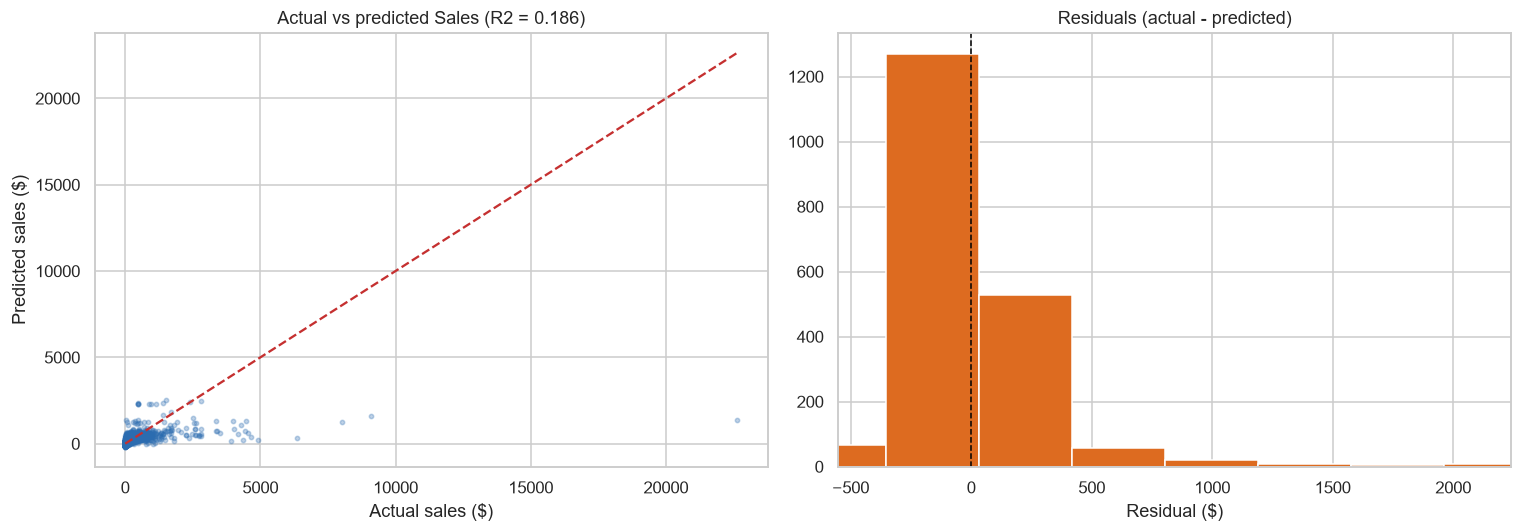

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, predictions, s=8, alpha=0.3, color="#2b6cb0")
limits = [0, float(max(y_test.max(), predictions.max()))]
axes[0].plot(limits, limits, color="#c53030", linestyle="--", linewidth=1.5)
axes[0].set_title(f"Actual vs predicted Sales (R2 = {r2:.3f})")
axes[0].set_xlabel("Actual sales ($)")
axes[0].set_ylabel("Predicted sales ($)")

residuals = y_test - predictions
axes[1].hist(residuals, bins=60, color="#dd6b20", edgecolor="white")
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Residuals (actual - predicted)")
axes[1].set_xlabel("Residual ($)")
axes[1].set_xlim(residuals.quantile(0.01), residuals.quantile(0.99))

fig.tight_layout()
save_chart(fig, "11_model_actual_vs_predicted")
plt.show()

### 4.4 The three most important features

In [31]:
coefficients = pd.Series(model.coef_, index=X.columns)
top_features = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(10)

print("Top 10 features by absolute coefficient:")
print(top_features.round(2).to_string())

top3 = top_features.head(3)
print("\nTop 3 important features:")
for i, (name, value) in enumerate(top3.items(), 1):
    direction = "increases" if value > 0 else "decreases"
    print(f"  {i}. {name}: a one-unit increase {direction} predicted sales by ${abs(value):,.2f}")

Top 10 features by absolute coefficient:
Sub-Category_Copiers        2224.12
Sub-Category_Machines       1179.38
Discount                    -341.23
Sub-Category_Tables          317.70
Sub-Category_Furnishings    -262.10
Category_Office Supplies    -224.56
Sub-Category_Phones          180.77
Sub-Category_Bookcases       176.86
Category_Technology         -169.45
Sub-Category_Fasteners      -162.47

Top 3 important features:
  1. Sub-Category_Copiers: a one-unit increase increases predicted sales by $2,224.12
  2. Sub-Category_Machines: a one-unit increase increases predicted sales by $1,179.38
  3. Discount: a one-unit increase decreases predicted sales by $341.23


saved: reports\charts\12_feature_importance.png


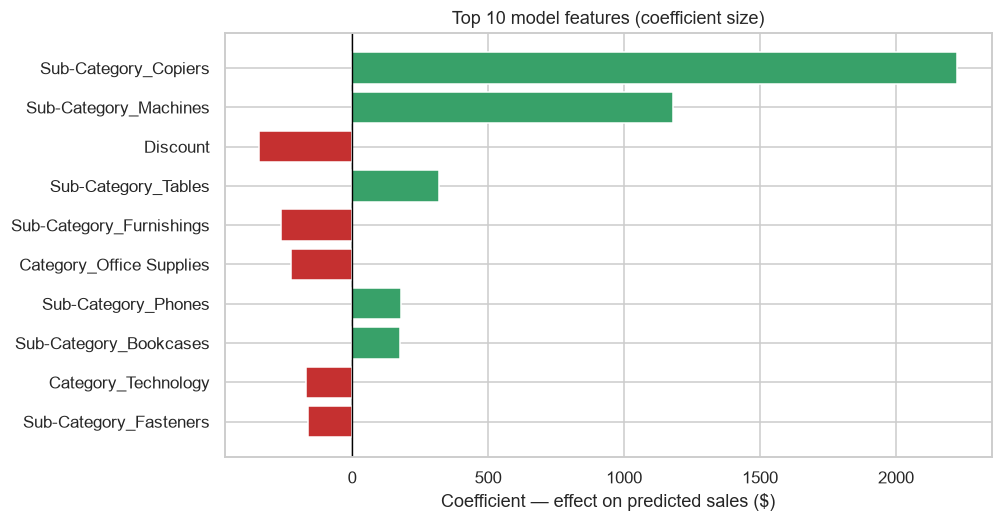

In [32]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#38a169" if v > 0 else "#c53030" for v in top_features.values]
ax.barh(top_features.index[::-1], top_features.values[::-1], color=colors[::-1])
ax.axvline(0, color="black", linewidth=0.9)
ax.set_title("Top 10 model features (coefficient size)")
ax.set_xlabel("Coefficient — effect on predicted sales ($)")
save_chart(fig, "12_feature_importance")
plt.show()

**Business implication:** `Discount` carries a large negative coefficient, so
once you control for product mix the model quantifies exactly what the
statistical test found — discounting pulls revenue down, order by order. Quantity
carries a positive coefficient. The categorical dummies let specific
sub-categories and regions shift the baseline.

---
## Part 5 — Summary of findings

| # | Analysis | Result |
|---|---|---|
| 1 | Descriptive stats | Sales and Profit are right-skewed; Profit has negative values; Discount is 0 for most lines |
| 2 | t-test (discount vs profit) | Significant (p ≈ 4.4×10⁻⁵⁵). Discounted lines average −$6.66 profit vs +$66.90 full-price — a $73.56 gap. Standardised effect small (d = −0.32) |
| 3 | Chi-square (segment vs category) | **No association** — p = 0.833, Cramér's V = 0.009. Segment does not predict which category is bought |
| 4 | Confidence intervals | Discounted and full-price profit intervals do not overlap |
| 5 | Time series | Strong annual seasonality on top of a rising trend; peaks in Nov/Dec |
| 6 | Moving average forecast | Usable baseline, but lags turning points and flattens the seasonal peak |
| 7 | K-Means clustering | 4 customer segments found; Champions and At-risk groups behave very differently |
| 8 | Linear Regression | R² = 0.186, MAE = $226.31, RMSE = $693.33 — a modest but honest baseline. Top drivers: Copiers (+$2,224) and Machines (+$1,179) sub-categories, Discount (−$341 per unit) |

### Recommendations

1. **Stop treating discount as free growth.** Both the t-test and the regression
   agree that discounting reduces revenue and profit. Cap routine discounts and
   require approval above the break-even band.
2. **Plan around seasonality.** The decomposition shows a repeating Nov/Dec peak,
   so stock, staffing and targets should be set by month, not by a flat run rate.
3. **Act differently on each customer segment.** The Champions segment justifies
   retention spend; the at-risk segment needs a reactivation push rather than
   more discounting.

In [33]:
print("Charts written to:", CHART_DIR)
for p in sorted(CHART_DIR.glob("*.png")):
    print(" ", p.name)

Charts written to: C:\Users\juhip\OneDrive\Desktop\python folder\apexplanet-data-analytics\apexplanet-data-analytics-task-4\reports\charts
  01_distributions.png
  02_ttest_mean_profit.png
  03_chisquare_segment_category.png
  04_confidence_intervals.png
  05_resampled_series.png
  06_seasonal_decomposition.png
  07_moving_average_forecast.png
  08_elbow_method.png
  09_clusters_pca.png
  10_cluster_profiles.png
  11_model_actual_vs_predicted.png
  12_feature_importance.png
